# Lab Exercise 6 — Demonstration and Comparative Analysis of LIME and SHAP
### Applied Machine Intelligence | Wine Recognition Dataset

**Goal:** classify wine samples into 3 cultivars from their chemical properties using a **Decision Tree**, a **Random Forest** and a **Logistic Regression** model, then explain individual predictions with **LIME** and **SHAP** inside the same program and compare the two explanation methods.

| Lab step | Where in this notebook |
|---|---|
| 1. Load + preprocess | Section 1 |
| 2. Train/test split | Section 2 |
| 3. Train 3 models + evaluate | Section 3 |
| 4. Pick a sample, predicted class + probabilities | Section 4 |
| 5. LIME local explanation (positive / negative features) | Section 5 |
| 6. SHAP values, local + global visualisations | Section 6 |
| 7. LIME vs SHAP for the same sample | Section 7 |
| 8. Repeat for another sample, analyse differences | Section 8 |
| 9. Discussion: similarities and differences | Sections 9 and 10 |

## 0. Install and import libraries

`lime` and `shap` are not pre-installed in Google Colab, so we install them first. `scikit-learn`, `pandas`, `numpy` and `matplotlib` are already available.

In [1]:
!pip install -q lime shap

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)

from lime.lime_tabular import LimeTabularExplainer
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully. SHAP version:", shap.__version__)

Libraries imported successfully. SHAP version: 0.54.1


## 1. Load the Wine dataset and preprocess (Lab step 1)

The Wine Recognition dataset has **178 samples**, **13 chemical features** (alcohol, flavanoids, proline, colour intensity, ...) and **3 classes** (three grape cultivars).

In [3]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()                      # 13 feature columns + 'target'
feature_names = list(wine.feature_names)
class_names = [str(c) for c in wine.target_names]

print("Dataset shape :", df.shape)
print("Features      :", feature_names)
print("Classes       :", class_names)
display(df.head())

Dataset shape : (178, 14)
Features      : ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Classes       : ['class_0', 'class_1', 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### Preprocessing checks

- **Missing values:** the dataset should have none.
- **Class balance:** check how many samples each class has.
- **Feature scales:** features have very different ranges (for example `proline` is in the hundreds, `hue` is around 1).

**Scaling decision:** tree-based models (Decision Tree, Random Forest) do not need scaling. Logistic Regression does, so its scaler is placed **inside a pipeline** (`StandardScaler` → `LogisticRegression`). This way every model receives the **raw, original-unit** feature values, and both LIME and SHAP explanations stay readable (for example `proline > 985`, not a scaled number).

In [4]:
print("Total missing values:", int(df.isnull().sum().sum()))

print("\nClass distribution:")
print(df["target"].map(dict(enumerate(class_names))).value_counts().sort_index())

print("\nFeature ranges (shows why scaling matters for Logistic Regression):")
display(df[feature_names].describe().T[["mean", "std", "min", "max"]].round(2))

X = df[feature_names].values
y = df["target"].values
print("\nX shape:", X.shape, "| y shape:", y.shape)

Total missing values: 0

Class distribution:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64

Feature ranges (shows why scaling matters for Logistic Regression):


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00



X shape: (178, 13) | y shape: (178,)


## 2. Split into training and testing sets (Lab step 2)

We keep 75% of the data for training and 25% for testing. `stratify=y` keeps the class proportions the same in both sets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape, "| Testing set:", X_test.shape)
print("Train class counts:", np.bincount(y_train))
print("Test  class counts:", np.bincount(y_test))

Training set: (133, 13) | Testing set: (45, 13)
Train class counts: [44 53 36]
Test  class counts: [15 18 12]


## 3. Train and evaluate Decision Tree, Random Forest and Logistic Regression (Lab step 3)

| Model | Settings | Note |
|---|---|---|
| Decision Tree | `max_depth=4` | A depth limit keeps the tree simple and reduces overfitting |
| Random Forest | `n_estimators=200` | Many trees voting together |
| Logistic Regression | scaler + `max_iter=1000` | Scaling is inside the pipeline |

Metrics: **accuracy**, **precision**, **recall**, **F1** (macro average, so each class counts equally), the **confusion matrix**, and 5-fold **cross-validation accuracy** on the training set.

In [6]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained.")

Decision Tree trained.
Random Forest trained.
Logistic Regression trained.


In [7]:
rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
        "5-fold CV accuracy": cross_val_score(model, X_train, y_train, cv=5).mean(),
    })
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

results = pd.DataFrame(rows).set_index("Model").round(4)
print("Summary of all models on the test set:")
display(results)

Decision Tree
              precision    recall  f1-score   support

     class_0      1.000     0.933     0.966        15
     class_1      0.900     1.000     0.947        18
     class_2      1.000     0.917     0.957        12

    accuracy                          0.956        45
   macro avg      0.967     0.950     0.956        45
weighted avg      0.960     0.956     0.956        45

Random Forest
              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        15
     class_1      1.000     1.000     1.000        18
     class_2      1.000     1.000     1.000        12

    accuracy                          1.000        45
   macro avg      1.000     1.000     1.000        45
weighted avg      1.000     1.000     1.000        45

Logistic Regression
              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        15
     class_1      1.000     1.000     1.000        18
     class_2      1.000    

,Accuracy,Precision (macro),Recall (macro),F1 (macro),5-fold CV accuracy
Model,,,,,
Decision Tree,0.9556,0.9667,0.95,0.9565,0.8954
Random Forest,1.0000,1.0000,1.00,1.0000,0.9698
Logistic Regression,1.0000,1.0000,1.00,1.0000,0.9849


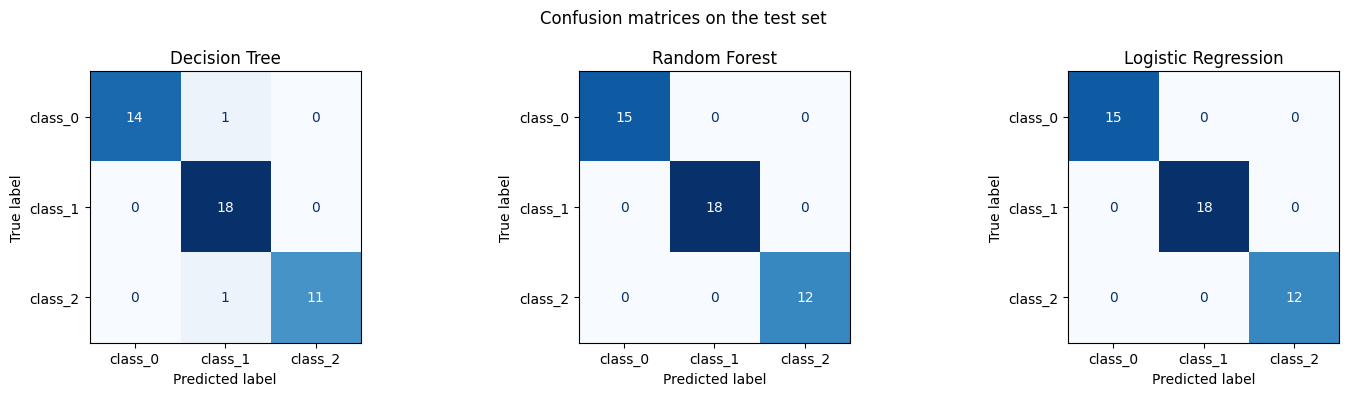

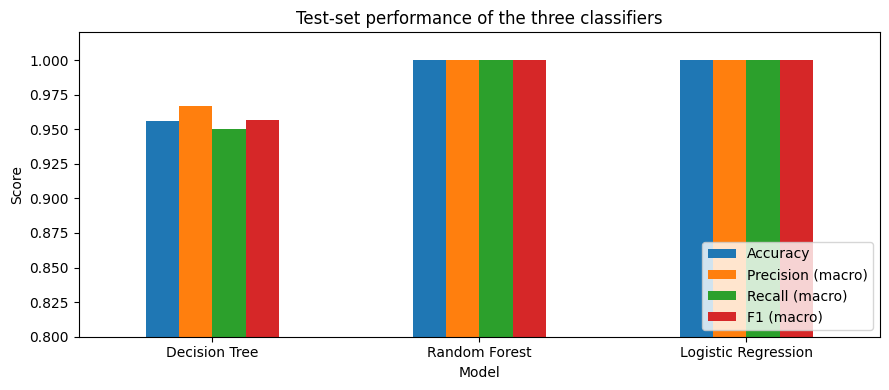

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=class_names,
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(f"{name}")
plt.suptitle("Confusion matrices on the test set")
plt.tight_layout()
plt.show()

results[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]].plot(
    kind="bar", figsize=(9, 4), ylim=(0.8, 1.02), rot=0
)
plt.title("Test-set performance of the three classifiers")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Reading the results:** all three models should score high on this dataset, because the three wine classes are well separated by their chemistry. Because performance is similar, the interesting question for the rest of the lab is **not** "which model is more accurate?" but **"why does each model decide the way it does, and do two explanation methods (LIME and SHAP) agree?"**.

## 4. Select individual test samples: predicted class and probabilities (Lab step 4)

- **Sample 1:** the first sample of the test set.
- **Sample 2:** the first test sample that belongs to a **different true class** than Sample 1. This gives a useful contrast in Step 8.

For each sample we show what **every model** predicts, along with the class probabilities. Both LIME and SHAP explain these probabilities.

In [9]:
idx_1 = 0
idx_2 = int(np.where(y_test != y_test[idx_1])[0][0])


def predicted_class(model_name, idx):
    return int(models[model_name].predict(X_test[idx].reshape(1, -1))[0])


def prediction_summary(idx):
    x = X_test[idx].reshape(1, -1)
    rows = []
    for name, model in models.items():
        proba = model.predict_proba(x)[0]
        pred = int(model.predict(x)[0])
        row = {"Model": name, "Predicted class": class_names[pred]}
        for c, p in zip(class_names, proba):
            row[f"P({c})"] = round(float(p), 4)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model")


for idx in (idx_1, idx_2):
    print("=" * 70)
    print(f"Test sample index {idx}  |  TRUE class: {class_names[y_test[idx]]}")
    print("=" * 70)
    print("Feature values of this sample:")
    display(pd.DataFrame({"value": X_test[idx]}, index=feature_names).round(3).T)
    print("Predictions and probabilities:")
    display(prediction_summary(idx))

Test sample index 0  |  TRUE class: class_0
Feature values of this sample:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
value,13.48,1.81,2.41,20.5,100.0,2.7,2.98,0.26,1.86,5.1,1.04,3.47,920.0


Predictions and probabilities:


,Predicted class,P(class_0),P(class_1),P(class_2)
Model,,,,
Decision Tree,class_0,1.0000,0.0000,0.0000
Random Forest,class_0,0.9350,0.0400,0.0250
Logistic Regression,class_0,0.9259,0.0725,0.0016


Test sample index 1  |  TRUE class: class_1
Feature values of this sample:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
value,12.29,2.83,2.22,18.0,88.0,2.45,2.25,0.25,1.99,2.15,1.15,3.3,290.0


Predictions and probabilities:


,Predicted class,P(class_0),P(class_1),P(class_2)
Model,,,,
Decision Tree,class_1,0.0000,1.0000,0.0000
Random Forest,class_1,0.0300,0.9650,0.0050
Logistic Regression,class_1,0.0038,0.9961,0.0001


In [10]:
# Extra: test samples where the three models do NOT agree (useful if you want a harder sample to explain)
all_preds = np.column_stack([m.predict(X_test) for m in models.values()])
disagree = np.where(~(all_preds == all_preds[:, [0]]).all(axis=1))[0]
print("Test samples where the three models disagree:", disagree.tolist() if len(disagree) else "none")

Test samples where the three models disagree: [28, 38]


## 5. LIME local explanation (Lab step 5)

### What is LIME? (in simple words)

**LIME** = *Local Interpretable Model-agnostic Explanations*. It explains **one prediction at a time**:

1. Take the test sample you want to explain.
2. Create thousands of slightly changed copies of it (**perturbations**).
3. Ask the model for its prediction on every copy.
4. Give more importance to copies that are **close** to the original sample.
5. Fit a **simple linear model** on these copies. Its coefficients are the explanation.

How to read a LIME result for the predicted class:
- **Positive weight** → this feature value pushes the prediction **towards** the predicted class.
- **Negative weight** → this feature value pushes the prediction **away from** the predicted class.

### 5.1 Create the LIME explainer

`LimeTabularExplainer` is given the **training data** so it can create realistic perturbations. Settings:

- `mode="classification"` → we explain class probabilities.
- `discretize_continuous=True` → numeric features are split into ranges (quartile bins), so explanations read like rules, for example `proline > 985`.
- `random_state` → makes the random perturbations repeatable.

The **same explainer** is used for all three models, so the feature ranges (rules) are comparable between models.

In [11]:
def make_explainer(seed=RANDOM_STATE):
    return LimeTabularExplainer(
        training_data=X_train,
        feature_names=feature_names,
        class_names=class_names,
        mode="classification",
        discretize_continuous=True,
        random_state=seed,
    )

explainer = make_explainer()
print("LIME explainer created.")

LIME explainer created.


### 5.2 Helper functions

- `lime_explain` → runs LIME for one sample and one model, **for the class the model predicted**.
- `lime_to_frame` → converts the explanation into a table (feature, rule, weight, effect).
- `show_lime` → prints the prediction, the **positive** and **negative** contributing features, and the LIME bar chart.

`num_features=8` means the explanation shows the 8 most influential features.

In [12]:
def lime_explain(model, idx, num_features=8, explainer_obj=None, num_samples=5000):
    explainer_obj = explainer_obj or explainer
    x = X_test[idx]
    pred = int(model.predict(x.reshape(1, -1))[0])
    exp = explainer_obj.explain_instance(
        data_row=x,
        predict_fn=model.predict_proba,
        labels=(pred,),
        num_features=num_features,
        num_samples=num_samples,
    )
    return exp, pred


def lime_to_frame(exp, pred):
    rules = exp.as_list(label=pred)                       # [(rule text, weight), ...]
    feature_ids = [i for i, _ in exp.as_map()[pred]]      # same order as the rules
    frame = pd.DataFrame({
        "Feature": [feature_names[i] for i in feature_ids],
        "LIME rule": [r for r, _ in rules],
        "Weight": [w for _, w in rules],
    })
    frame["Effect"] = np.where(frame["Weight"] > 0,
                               "supports " + class_names[pred],
                               "opposes " + class_names[pred])
    return frame


lime_results = {}   # (sample index, model name) -> (explanation, predicted class, table)
lime_times = {}     # model name -> list of seconds per LIME explanation


def show_lime(model_name, idx, num_features=8):
    model = models[model_name]
    t0 = time.perf_counter()
    exp, pred = lime_explain(model, idx, num_features)
    lime_times.setdefault(model_name, []).append(time.perf_counter() - t0)
    frame = lime_to_frame(exp, pred)
    lime_results[(idx, model_name)] = (exp, pred, frame)

    proba = model.predict_proba(X_test[idx].reshape(1, -1))[0]
    score = exp.score[pred] if isinstance(exp.score, dict) else exp.score

    print("=" * 70)
    print(f"LIME  |  Model: {model_name}  |  Test sample: {idx}")
    print("=" * 70)
    print(f"True class      : {class_names[y_test[idx]]}")
    print(f"Predicted class : {class_names[pred]}")
    print("Probabilities   : " + ", ".join(f"{c}={p:.3f}" for c, p in zip(class_names, proba)))
    print(f"Local surrogate fit (R^2): {score:.3f}   (closer to 1 = the simple model mimics the black box better here)")

    pos = frame[frame["Weight"] > 0]
    neg = frame[frame["Weight"] < 0]
    print(f"\nFeatures pushing TOWARDS '{class_names[pred]}' (positive weights):")
    display(pos[["Feature", "LIME rule", "Weight"]].round(4).reset_index(drop=True))
    print(f"Features pushing AWAY from '{class_names[pred]}' (negative weights):")
    display(neg[["Feature", "LIME rule", "Weight"]].round(4).reset_index(drop=True))

    exp.as_pyplot_figure(label=pred)
    plt.gcf().set_size_inches(8, 4.5)
    plt.title(f"LIME - {model_name} - sample {idx} - predicted: {class_names[pred]}")
    plt.tight_layout()
    plt.show()

### 5.3 LIME for Sample 1 with all three classifiers

In each chart, **green bars** (positive) support the predicted class and **red bars** (negative) oppose it.

LIME  |  Model: Decision Tree  |  Test sample: 0
True class      : class_0
Predicted class : class_0
Probabilities   : class_0=1.000, class_1=0.000, class_2=0.000
Local surrogate fit (R^2): 0.111   (closer to 1 = the simple model mimics the black box better here)

Features pushing TOWARDS 'class_0' (positive weights):


,Feature,LIME rule,Weight
0,proline,675.00 < proline <= 985.00,0.1996
1,color_intensity,4.68 < color_intensity <= 6.25,0.1788
2,flavanoids,flavanoids > 2.78,0.1705
3,od280/od315_of_diluted_wines,od280/od315_of_diluted_wines > 3.14,0.0062


Features pushing AWAY from 'class_0' (negative weights):


,Feature,LIME rule,Weight
0,malic_acid,1.61 < malic_acid <= 1.81,-0.0320
1,alcalinity_of_ash,20.00 < alcalinity_of_ash <= 21.50,-0.0166
2,nonflavanoid_phenols,nonflavanoid_phenols <= 0.27,-0.0108
3,ash,2.36 < ash <= 2.56,-0.0090


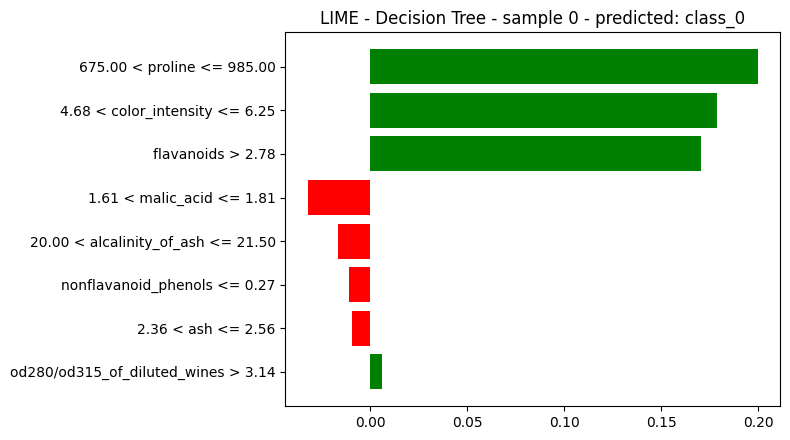

In [13]:
show_lime("Decision Tree", idx_1)

LIME  |  Model: Random Forest  |  Test sample: 0
True class      : class_0
Predicted class : class_0
Probabilities   : class_0=0.935, class_1=0.040, class_2=0.025
Local surrogate fit (R^2): 0.188   (closer to 1 = the simple model mimics the black box better here)

Features pushing TOWARDS 'class_0' (positive weights):


,Feature,LIME rule,Weight
0,alcohol,12.99 < alcohol <= 13.56,0.1058
1,flavanoids,flavanoids > 2.78,0.1055
2,color_intensity,4.68 < color_intensity <= 6.25,0.0699
3,proline,675.00 < proline <= 985.00,0.0606
4,od280/od315_of_diluted_wines,od280/od315_of_diluted_wines > 3.14,0.0584
5,total_phenols,2.40 < total_phenols <= 2.80,0.0426
6,hue,0.96 < hue <= 1.09,0.0235
7,magnesium,98.00 < magnesium <= 108.00,0.0176


Features pushing AWAY from 'class_0' (negative weights):


,Feature,LIME rule,Weight


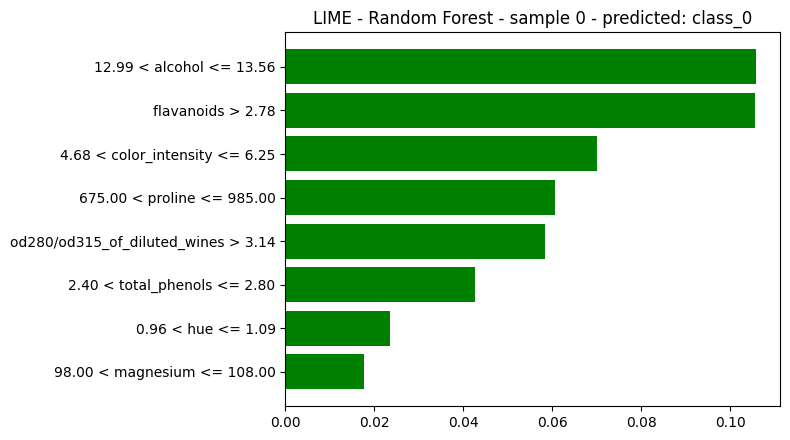

In [14]:
show_lime("Random Forest", idx_1)

LIME  |  Model: Logistic Regression  |  Test sample: 0
True class      : class_0
Predicted class : class_0
Probabilities   : class_0=0.926, class_1=0.072, class_2=0.002
Local surrogate fit (R^2): 0.097   (closer to 1 = the simple model mimics the black box better here)

Features pushing TOWARDS 'class_0' (positive weights):


,Feature,LIME rule,Weight
0,od280/od315_of_diluted_wines,od280/od315_of_diluted_wines > 3.14,0.1667
1,flavanoids,flavanoids > 2.78,0.1596
2,alcohol,12.99 < alcohol <= 13.56,0.0534
3,color_intensity,4.68 < color_intensity <= 6.25,0.0407
4,total_phenols,2.40 < total_phenols <= 2.80,0.0381
5,ash,2.36 < ash <= 2.56,0.0328
6,proline,675.00 < proline <= 985.00,0.0273


Features pushing AWAY from 'class_0' (negative weights):


,Feature,LIME rule,Weight
0,alcalinity_of_ash,20.00 < alcalinity_of_ash <= 21.50,-0.0845


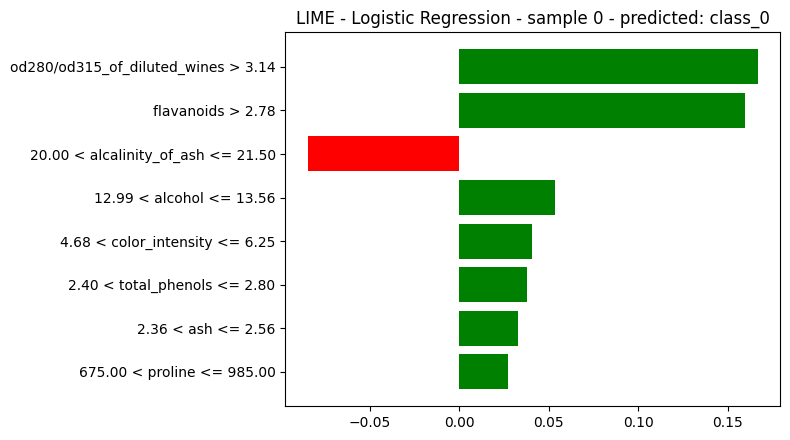

In [15]:
show_lime("Logistic Regression", idx_1)

## 6. SHAP: feature contributions using Shapley values (Lab step 6)

### What is SHAP? (in simple words)

**SHAP** = *SHapley Additive exPlanations*. It uses **Shapley values** from game theory.

**Analogy:** a team of 13 players (the features) wins a prize (the model's predicted probability for a class). How much of the prize should each player get? The fair share of a player is its **average extra contribution over all possible orders in which the team could be formed**. That average is the Shapley value.

How to read SHAP for the predicted class:
- The **base value** is the model's average prediction over the data (the starting point).
- A **positive SHAP value** pushes the probability **up** from the base value.
- A **negative SHAP value** pushes the probability **down**.
- **Additivity:** `base value + sum of all SHAP values = the model's predicted probability`. LIME does not have this property.

### Explainers used

| Model | SHAP explainer | Why |
|---|---|---|
| Decision Tree | `TreeExplainer` | Fast and exact for tree models |
| Random Forest | `TreeExplainer` | Fast and exact for tree ensembles |
| Logistic Regression (pipeline) | `KernelExplainer` | Model-agnostic, works on the raw features through `predict_proba`. A background set of 10 k-means centres of the training data keeps it fast |

We compute SHAP values for the **whole test set** once. That gives local explanations (one row) and global explanations (average over all rows).

**About the output format:** newer SHAP versions return a 3-D array (samples × features × classes), older versions return a list with one array per class. The helper `to_3d` converts either to the same 3-D shape.

In [16]:
def to_3d(sv):
    # Convert SHAP output to an array of shape (n_samples, n_features, n_classes)
    arr = np.stack([np.asarray(s) for s in sv], axis=-1) if isinstance(sv, list) else np.asarray(sv)
    n, f, c = len(X_test), len(feature_names), len(class_names)
    if arr.ndim == 3 and arr.shape == (c, n, f):
        arr = np.moveaxis(arr, 0, -1)
    if arr.shape != (n, f, c):
        raise ValueError(f"Unexpected SHAP output shape {arr.shape}; expected {(n, f, c)}")
    return arr


background = shap.kmeans(X_train, 10)     # small background set for Kernel SHAP

shap_3d, shap_base, shap_times = {}, {}, {}

for name, model in models.items():
    t0 = time.perf_counter()
    if name == "Logistic Regression":
        shap_explainer = shap.KernelExplainer(model.predict_proba, background)
        raw = shap_explainer.shap_values(X_test, nsamples=1000, silent=True)
    else:
        shap_explainer = shap.TreeExplainer(model)
        raw = shap_explainer.shap_values(X_test, check_additivity=False)
    shap_times[name] = time.perf_counter() - t0
    shap_3d[name] = to_3d(raw)
    shap_base[name] = np.asarray(shap_explainer.expected_value, dtype=float).reshape(-1)
    print(f"{name:20s} SHAP array shape: {shap_3d[name].shape}  |  time for all {len(X_test)} test samples: {shap_times[name]:.2f}s")

Decision Tree        SHAP array shape: (45, 13, 3)  |  time for all 45 test samples: 0.00s
Random Forest        SHAP array shape: (45, 13, 3)  |  time for all 45 test samples: 0.07s
Logistic Regression  SHAP array shape: (45, 13, 3)  |  time for all 45 test samples: 3.62s


### 6.1 Check the additivity property

For every test sample and class: **base value + sum of SHAP values should equal the model's predicted probability**. The table shows the largest difference found (it should be very close to 0).

In [17]:
rows = []
for name, model in models.items():
    proba = model.predict_proba(X_test)                                  # (n_samples, n_classes)
    rebuilt = shap_base[name][None, :] + shap_3d[name].sum(axis=1)       # base + sum of SHAP values
    rows.append({"Model": name,
                 "Max |base + sum(SHAP) - probability|": float(np.abs(rebuilt - proba).max())})
display(pd.DataFrame(rows).set_index("Model").round(6))

,Max |base + sum(SHAP) - probability|
Model,
Decision Tree,0.0
Random Forest,0.0
Logistic Regression,0.0


### 6.2 SHAP helper functions

- `shap_series` → the SHAP values (one per feature) for one sample and the **predicted class**.
- `safe_run` → runs a plotting function and prints a short message instead of stopping the notebook if a plot fails in a particular SHAP version.
- `show_shap` → prints the base value, prediction, the features pushing **up** and **down**, a bar chart, and the SHAP **waterfall plot**.

In [18]:
def shap_series(model_name, idx):
    c = predicted_class(model_name, idx)
    return pd.Series(shap_3d[model_name][idx, :, c], index=feature_names)


def safe_run(fn, label):
    try:
        fn()
    except Exception as e:
        plt.close("all")
        print(f"[{label} could not be drawn in this SHAP version: {type(e).__name__}: {e}]")


def show_shap(model_name, idx, top_n=8):
    c = predicted_class(model_name, idx)
    vals = shap_series(model_name, idx)
    base = float(shap_base[model_name][c])
    proba = float(models[model_name].predict_proba(X_test[idx].reshape(1, -1))[0][c])

    frame = pd.DataFrame({"Feature": feature_names,
                          "Feature value": X_test[idx],
                          "SHAP value": vals.values})
    frame = frame.reindex(frame["SHAP value"].abs().sort_values(ascending=False).index).reset_index(drop=True)

    print("=" * 70)
    print(f"SHAP  |  Model: {model_name}  |  Test sample: {idx}")
    print("=" * 70)
    print(f"True class      : {class_names[y_test[idx]]}")
    print(f"Predicted class : {class_names[c]}   (probability = {proba:.3f})")
    print(f"Base value (average model output for this class) : {base:.3f}")
    print(f"Sum of SHAP values                                 : {vals.sum():+.3f}")
    print(f"Base + sum of SHAP = {base + vals.sum():.3f}  (equals the predicted probability)")

    pos = frame[frame["SHAP value"] > 1e-9].head(top_n)
    neg = frame[frame["SHAP value"] < -1e-9].head(top_n)
    print(f"\nFeatures pushing the probability of '{class_names[c]}' UP (positive SHAP values):")
    display(pos.round(4))
    print(f"Features pushing the probability of '{class_names[c]}' DOWN (negative SHAP values):")
    if len(neg):
        display(neg.round(4))
    else:
        print("none (no feature pushes the probability down)")

    # local bar chart
    top = frame.head(top_n).iloc[::-1]
    plt.figure(figsize=(8, 4.5))
    plt.barh(top["Feature"], top["SHAP value"],
             color=["tab:green" if v > 0 else "tab:red" for v in top["SHAP value"]])
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("SHAP value (change in probability)")
    plt.title(f"SHAP - {model_name} - sample {idx} - predicted: {class_names[c]}")
    plt.tight_layout()
    plt.show()

    # local waterfall plot
    def _waterfall():
        e = shap.Explanation(values=vals.values, base_values=base,
                             data=X_test[idx], feature_names=feature_names)
        shap.plots.waterfall(e, max_display=top_n + 1, show=False)
        plt.gcf().set_size_inches(8, 5)
        plt.tight_layout()
        plt.show()
    print("Waterfall plot: starts at the base value and adds each feature's SHAP value to reach the prediction.")
    safe_run(_waterfall, "waterfall plot")

### 6.3 Local SHAP explanations for Sample 1 (all three models)

SHAP  |  Model: Decision Tree  |  Test sample: 0
True class      : class_0
Predicted class : class_0   (probability = 1.000)
Base value (average model output for this class) : 0.331
Sum of SHAP values                                 : +0.669
Base + sum of SHAP = 1.000  (equals the predicted probability)

Features pushing the probability of 'class_0' UP (positive SHAP values):


,Feature,Feature value,SHAP value
0,flavanoids,2.98,0.3348
1,color_intensity,5.10,0.2578
2,proline,920.00,0.0897


Features pushing the probability of 'class_0' DOWN (negative SHAP values):


,Feature,Feature value,SHAP value
3,malic_acid,1.81,-0.0057
4,od280/od315_of_diluted_wines,3.47,-0.0038
5,ash,2.41,-0.0037


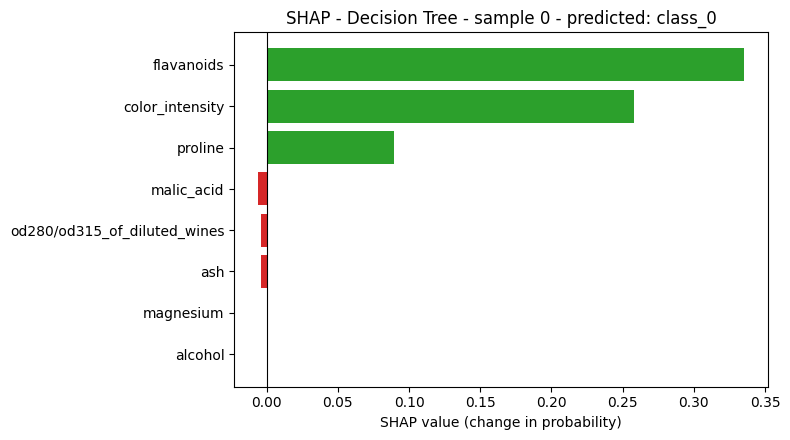

Waterfall plot: starts at the base value and adds each feature's SHAP value to reach the prediction.


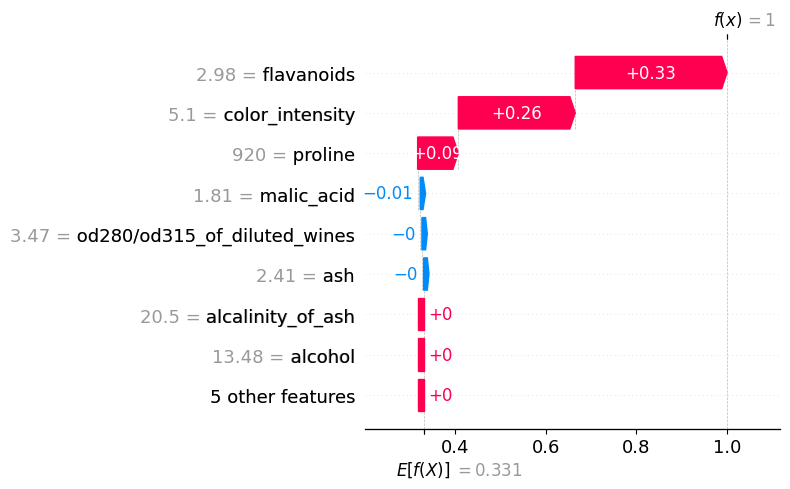

In [19]:
show_shap("Decision Tree", idx_1)

SHAP  |  Model: Random Forest  |  Test sample: 0
True class      : class_0
Predicted class : class_0   (probability = 0.935)
Base value (average model output for this class) : 0.329
Sum of SHAP values                                 : +0.606
Base + sum of SHAP = 0.935  (equals the predicted probability)

Features pushing the probability of 'class_0' UP (positive SHAP values):


,Feature,Feature value,SHAP value
0,flavanoids,2.98,0.1193
1,alcohol,13.48,0.1162
2,proline,920.00,0.1044
3,color_intensity,5.10,0.1013
4,od280/od315_of_diluted_wines,3.47,0.0577
5,total_phenols,2.70,0.0360
6,hue,1.04,0.0354
7,proanthocyanins,1.86,0.0187


Features pushing the probability of 'class_0' DOWN (negative SHAP values):


,Feature,Feature value,SHAP value
8,alcalinity_of_ash,20.50,-0.0181
12,ash,2.41,-0.0006


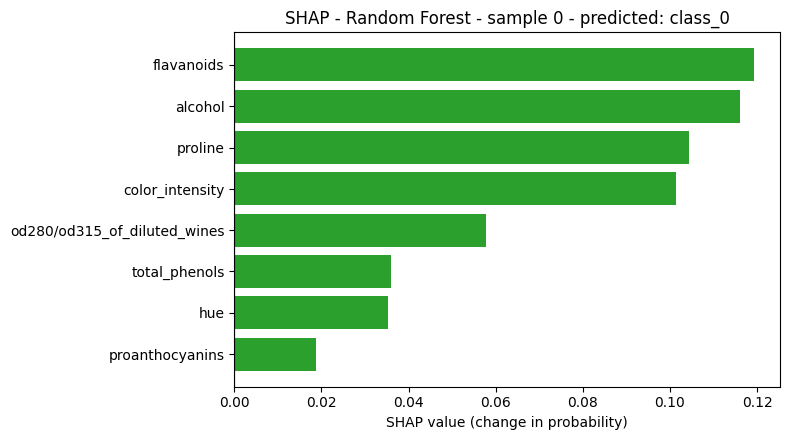

Waterfall plot: starts at the base value and adds each feature's SHAP value to reach the prediction.


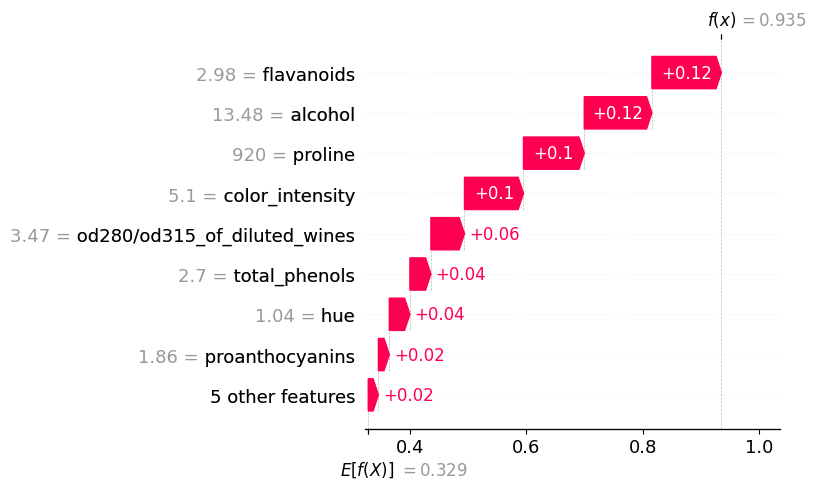

In [20]:
show_shap("Random Forest", idx_1)

SHAP  |  Model: Logistic Regression  |  Test sample: 0
True class      : class_0
Predicted class : class_0   (probability = 0.926)
Base value (average model output for this class) : 0.355
Sum of SHAP values                                 : +0.571
Base + sum of SHAP = 0.926  (equals the predicted probability)

Features pushing the probability of 'class_0' UP (positive SHAP values):


,Feature,Feature value,SHAP value
0,proline,920.00,0.1796
1,alcohol,13.48,0.1377
2,od280/od315_of_diluted_wines,3.47,0.1339
3,flavanoids,2.98,0.0973
5,total_phenols,2.70,0.0208
6,nonflavanoid_phenols,0.26,0.0202
8,ash,2.41,0.0183
9,color_intensity,5.10,0.0133


Features pushing the probability of 'class_0' DOWN (negative SHAP values):


,Feature,Feature value,SHAP value
4,malic_acid,1.81,-0.0314
7,hue,1.04,-0.0187


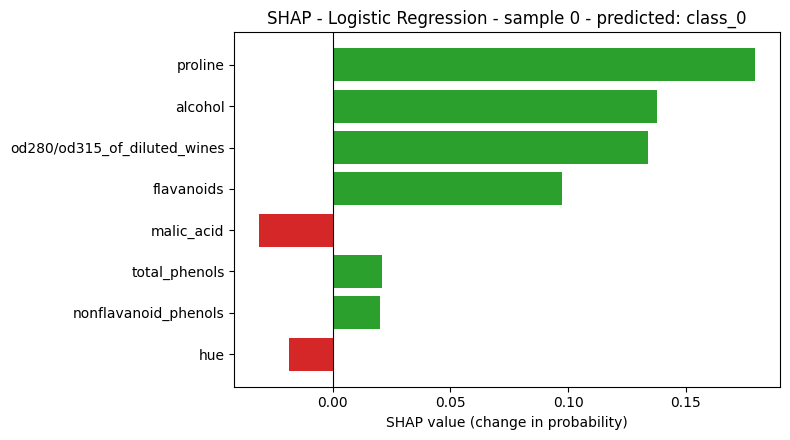

Waterfall plot: starts at the base value and adds each feature's SHAP value to reach the prediction.


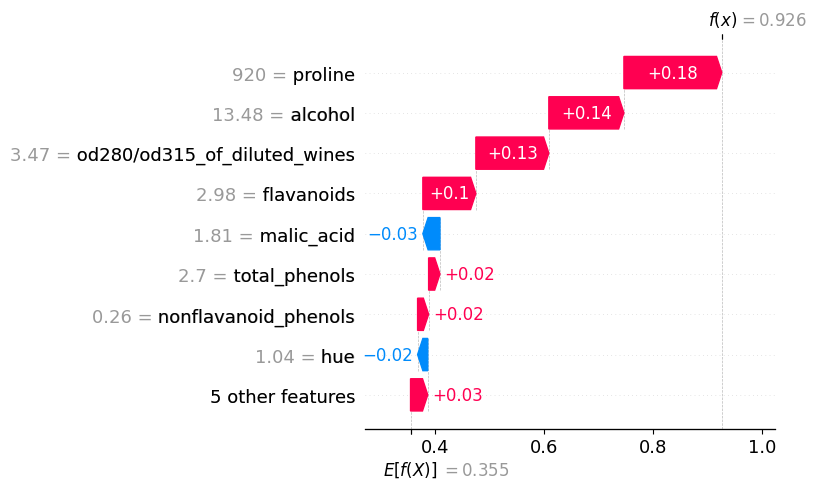

In [21]:
show_shap("Logistic Regression", idx_1)

### 6.4 Global SHAP explanations

A **global** explanation summarises the model over **all test samples**. The global importance of a feature is its **mean absolute SHAP value** (averaged over all test samples and the three classes). A high value means the feature matters a lot to the model overall.

Global importance = mean |SHAP value| (sorted by Random Forest):


,Decision Tree,Random Forest,Logistic Regression
color_intensity,0.2069,0.0873,0.0619
flavanoids,0.1895,0.0813,0.0569
proline,0.1017,0.0777,0.0992
alcohol,0.0000,0.0690,0.0725
od280/od315_of_diluted_wines,0.0146,0.0453,0.0438
hue,0.0000,0.0444,0.0522
total_phenols,0.0000,0.0188,0.0118
malic_acid,0.0146,0.0151,0.0360
proanthocyanins,0.0000,0.0134,0.0223
magnesium,0.0000,0.0123,0.0046


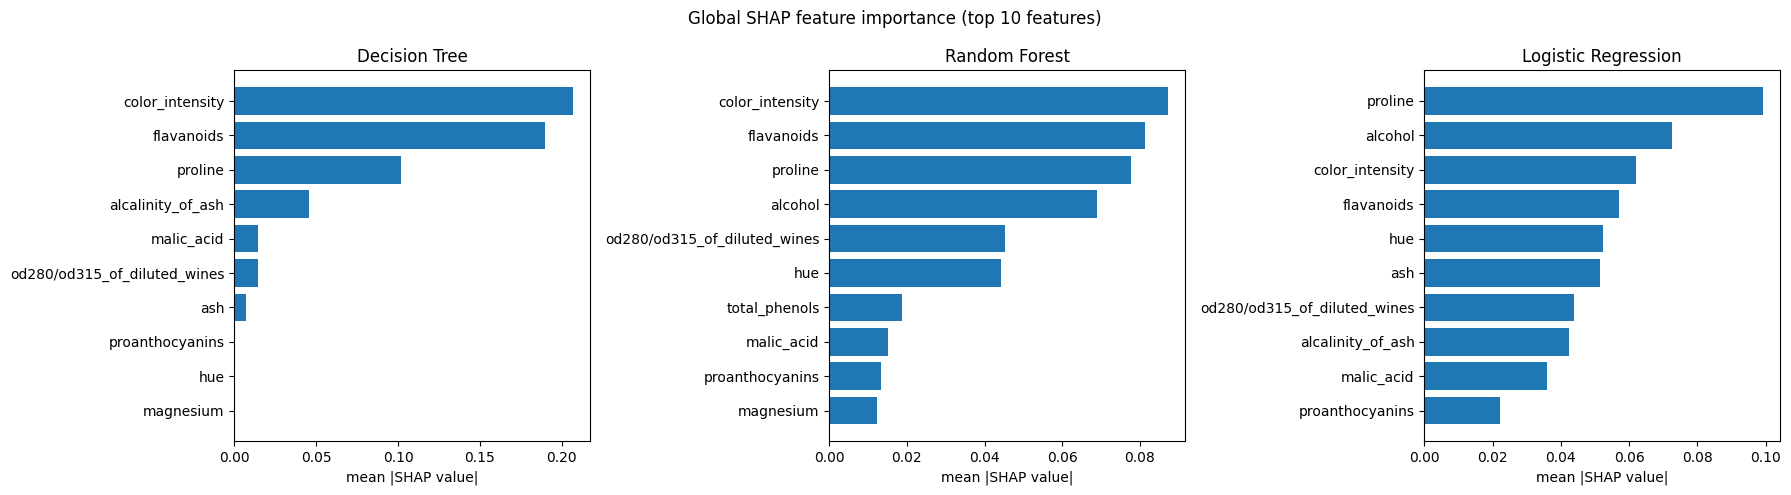

In [22]:
global_df = pd.DataFrame(
    {name: np.abs(shap_3d[name]).mean(axis=(0, 2)) for name in models},
    index=feature_names
)
print("Global importance = mean |SHAP value| (sorted by Random Forest):")
display(global_df.sort_values("Random Forest", ascending=False).round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, models):
    s = global_df[name].sort_values().tail(10)
    ax.barh(s.index, s.values, color="tab:blue")
    ax.set_title(f"{name}")
    ax.set_xlabel("mean |SHAP value|")
plt.suptitle("Global SHAP feature importance (top 10 features)")
plt.tight_layout()
plt.show()

**Summary (beeswarm) plots** show every test sample as a dot for each feature. The horizontal position is the SHAP value, and the colour is the feature value (red = high, blue = low). This shows not only *which* features matter but also *how*: for example, whether high values of a feature push towards the class or away from it. We draw one for the class predicted for Sample 1.

Summary plots for class: class_0


/tmp/ipykernel_815/1688053373.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_3d[name][:, :, focus_class], X_test,


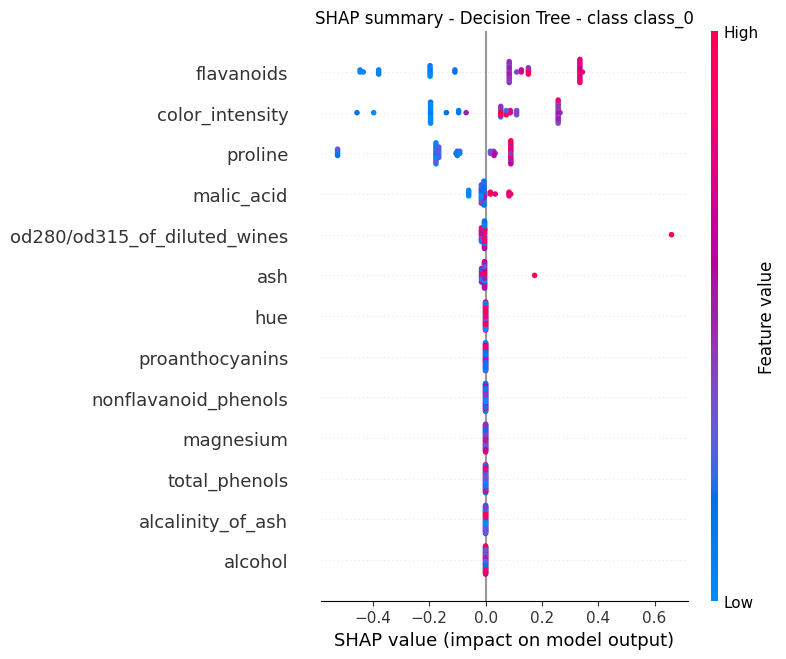

/tmp/ipykernel_815/1688053373.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_3d[name][:, :, focus_class], X_test,


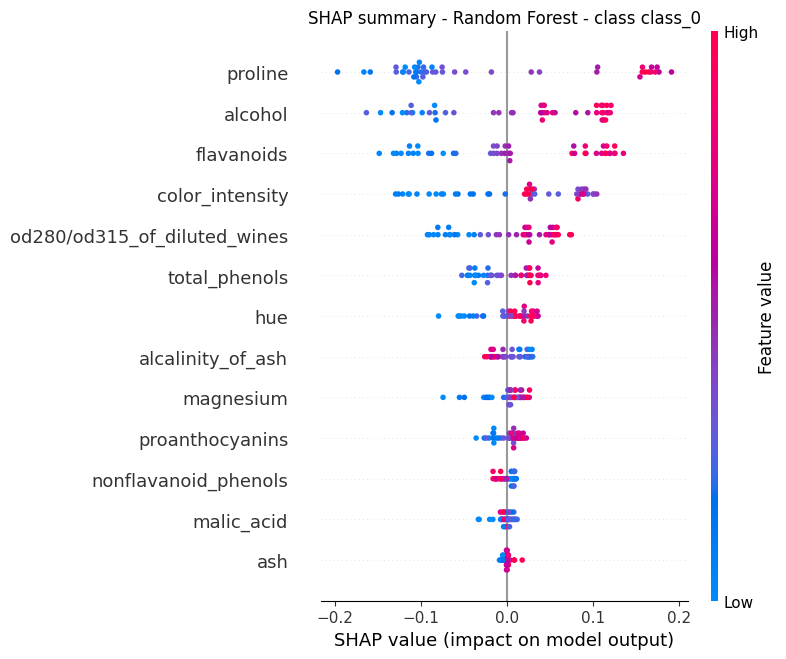

/tmp/ipykernel_815/1688053373.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_3d[name][:, :, focus_class], X_test,


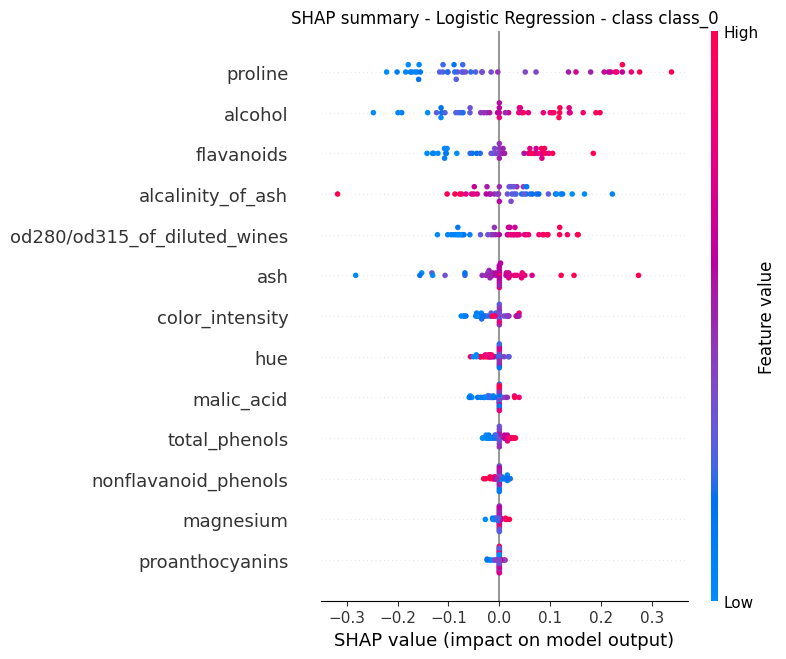

In [23]:
focus_class = predicted_class("Random Forest", idx_1)
print(f"Summary plots for class: {class_names[focus_class]}")

for name in models:
    def _summary():
        shap.summary_plot(shap_3d[name][:, :, focus_class], X_test,
                          feature_names=feature_names, show=False)
        plt.title(f"SHAP summary - {name} - class {class_names[focus_class]}")
        plt.tight_layout()
        plt.show()
    safe_run(_summary, f"summary plot ({name})")

## 7. Display and compare LIME and SHAP for the same sample (Lab step 7)

For each model we compare the two explanations of the **same prediction** for **Sample 1**. They are not measured in the same units: LIME weights belong to a local linear model on binned features, while SHAP values are changes in probability. So we compare them by:

- **Sign agreement:** do both say the feature pushes towards (+) or away from (−) the predicted class?
- **Rank agreement (Spearman):** do both rank the features' importance in a similar order? (1 = identical order, 0 = unrelated)
- **Top-3 overlap:** how many of the 3 most important features are the same?

To make the comparison fair, LIME is run here with `num_features=13`, so it scores **all** features, just like SHAP.

################################################################################
LIME vs SHAP | test sample 0 | true class: class_0
################################################################################

Decision Tree - predicted class: class_0


,Feature value,LIME weight,LIME rank,SHAP value,SHAP rank,Same sign?
color_intensity,5.10,0.1951,1,0.2578,2,yes
flavanoids,2.98,0.1496,3,0.3348,1,yes
proline,920.00,0.1765,2,0.0897,3,yes
malic_acid,1.81,-0.0378,4,-0.0057,4,yes
nonflavanoid_phenols,0.26,0.0265,5,0.0000,7,n/a
od280/od315_of_diluted_wines,3.47,0.0237,6,-0.0038,5,NO
magnesium,100.00,0.0116,7,0.0000,7,n/a
alcohol,13.48,0.0107,8,0.0000,7,n/a



Random Forest - predicted class: class_0


,Feature value,LIME weight,LIME rank,SHAP value,SHAP rank,Same sign?
flavanoids,2.98,0.1086,1,0.1193,1,yes
alcohol,13.48,0.1037,2,0.1162,2,yes
color_intensity,5.10,0.0723,3,0.1013,4,yes
proline,920.00,0.0607,5,0.1044,3,yes
od280/od315_of_diluted_wines,3.47,0.0652,4,0.0577,5,yes
total_phenols,2.70,0.0305,6,0.0360,6,yes
hue,1.04,0.0196,8,0.0354,7,yes
magnesium,100.00,0.0247,7,0.0138,10,yes



Logistic Regression - predicted class: class_0


,Feature value,LIME weight,LIME rank,SHAP value,SHAP rank,Same sign?
od280/od315_of_diluted_wines,3.47,0.1506,1,0.1339,3,yes
flavanoids,2.98,0.1505,2,0.0973,4,yes
proline,920.00,0.0480,6,0.1796,1,yes
alcohol,13.48,0.0520,5,0.1377,2,yes
alcalinity_of_ash,20.50,-0.0803,3,0.0000,11,n/a
ash,2.41,0.0575,4,0.0183,9,yes
malic_acid,1.81,-0.0346,8,-0.0314,5,yes
nonflavanoid_phenols,0.26,0.0436,7,0.0202,7,yes


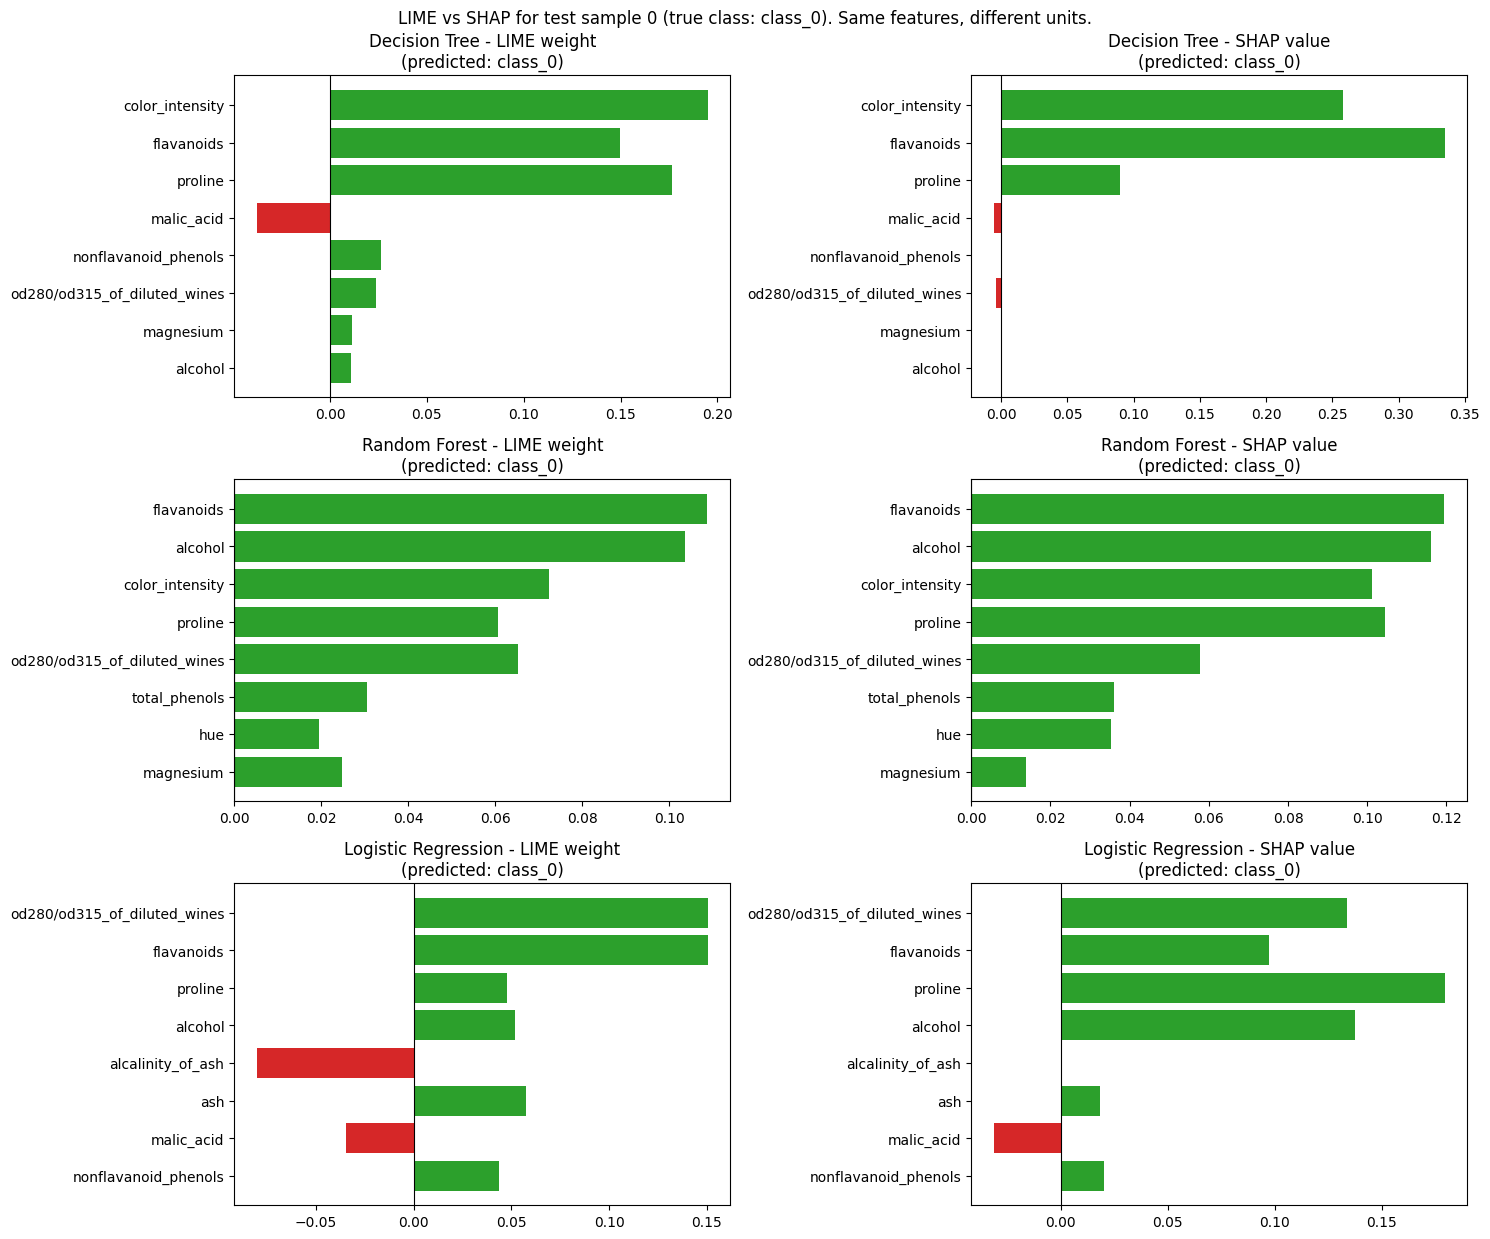

Agreement between LIME and SHAP for this sample:


,Spearman rank corr.,Top-3 overlap,Sign agreement (%)
Model,,,
Decision Tree,0.800,3,83.3
Random Forest,0.923,2,92.3
Logistic Regression,0.492,1,100.0


In [24]:
lime_full = {}          # (sample index, model name) -> LIME weights for all 13 features
lime_shap_tables = {}   # (sample index, model name) -> comparison table
metric_rows = []        # agreement metrics for every (sample, model)


def lime_all_features(model_name, idx):
    key = (idx, model_name)
    if key not in lime_full:
        exp, pred = lime_explain(models[model_name], idx, num_features=len(feature_names))
        frame = lime_to_frame(exp, pred)
        lime_full[key] = frame.set_index("Feature")["Weight"].reindex(feature_names).fillna(0.0)
    return lime_full[key]


def compare_lime_shap(idx, model_name):
    comp = pd.DataFrame({
        "LIME weight": lime_all_features(model_name, idx),
        "SHAP value": shap_series(model_name, idx),
    })
    comp["Feature value"] = X_test[idx]
    comp["LIME rank"] = comp["LIME weight"].abs().rank(ascending=False, method="min").astype(int)
    comp["SHAP rank"] = comp["SHAP value"].abs().rank(ascending=False, method="min").astype(int)
    both = (comp["LIME weight"].abs() > 1e-9) & (comp["SHAP value"].abs() > 1e-9)
    same = np.sign(comp["LIME weight"]) == np.sign(comp["SHAP value"])
    comp["Same sign?"] = np.where(both, np.where(same, "yes", "NO"), "n/a")
    norm = lambda s: s.abs() / (s.abs().max() or 1.0)
    comp["_score"] = norm(comp["LIME weight"]) + norm(comp["SHAP value"])
    return comp.sort_values("_score", ascending=False)


def agreement_metrics(comp, top_k=3):
    a = comp["LIME weight"].abs()
    b = comp["SHAP value"].abs()
    spearman = float(np.corrcoef(a.rank(), b.rank())[0, 1]) if a.nunique() > 1 and b.nunique() > 1 else np.nan
    top_lime = set(a.nlargest(top_k).index)
    top_shap = set(b[b > 1e-9].nlargest(top_k).index)
    both = (a > 1e-9) & (b > 1e-9)
    sign_agree = float((np.sign(comp.loc[both, "LIME weight"]) == np.sign(comp.loc[both, "SHAP value"])).mean() * 100) if both.any() else np.nan
    return {"Spearman rank corr.": round(spearman, 3),
            f"Top-{top_k} overlap": len(top_lime & top_shap),
            "Sign agreement (%)": round(sign_agree, 1)}


def plot_lime_vs_shap(idx, top_n=8):
    fig, axes = plt.subplots(len(models), 2, figsize=(15, 4.2 * len(models)))
    for r, name in enumerate(models):
        comp = lime_shap_tables[(idx, name)]
        feats = list(comp.head(top_n).index)[::-1]
        pred = predicted_class(name, idx)
        for ax, col, title in ((axes[r, 0], "LIME weight", "LIME weight"),
                               (axes[r, 1], "SHAP value", "SHAP value")):
            v = comp.loc[feats, col]
            ax.barh(feats, v, color=["tab:green" if x > 0 else "tab:red" for x in v])
            ax.axvline(0, color="black", linewidth=0.8)
            ax.set_title(f"{name} - {title}\n(predicted: {class_names[pred]})")
    plt.suptitle(f"LIME vs SHAP for test sample {idx} (true class: {class_names[y_test[idx]]}). Same features, different units.")
    plt.tight_layout()
    plt.show()


def run_comparison(idx, top_k=3):
    print("#" * 80)
    print(f"LIME vs SHAP | test sample {idx} | true class: {class_names[y_test[idx]]}")
    print("#" * 80)
    for name in models:
        comp = compare_lime_shap(idx, name)
        lime_shap_tables[(idx, name)] = comp
        metric_rows[:] = [r for r in metric_rows if not (r["Sample"] == idx and r["Model"] == name)]
        metric_rows.append({"Sample": idx, "Model": name, **agreement_metrics(comp, top_k)})
        pred = predicted_class(name, idx)
        print(f"\n{name} - predicted class: {class_names[pred]}")
        display(comp.head(8)[["Feature value", "LIME weight", "LIME rank", "SHAP value", "SHAP rank", "Same sign?"]].round(4))
    plot_lime_vs_shap(idx)
    print("Agreement between LIME and SHAP for this sample:")
    display(pd.DataFrame([r for r in metric_rows if r["Sample"] == idx]).drop(columns="Sample").set_index("Model"))


run_comparison(idx_1)

**How to read the comparison**

- **Same sign = "yes"** means LIME and SHAP agree about the direction in which that feature acts.
- Features with a high rank in both columns are the ones both methods consider most important.
- Differences are expected: LIME explains a **simple model fitted around the sample**, while SHAP **distributes the prediction fairly over the features**. For a Decision Tree, SHAP gives exactly 0 to features the tree never splits on, while LIME may still give them small non-zero weights because of its random sampling.

### 7.1 Do the three models use the same features? (Sample 1)

The tables show the top features by importance for each model, first with SHAP and then with LIME.

In [25]:
def cross_model_shap(idx, top_n=10):
    t = pd.DataFrame({name: shap_series(name, idx) for name in models})
    return t.loc[t.abs().max(axis=1).sort_values(ascending=False).index].head(top_n)


def cross_model_lime(idx, top_n=10):
    t = pd.DataFrame({name: lime_all_features(name, idx) for name in models})
    return t.loc[t.abs().max(axis=1).sort_values(ascending=False).index].head(top_n)


print(f"SHAP values per model - sample {idx_1}")
display(cross_model_shap(idx_1).round(4))
print(f"LIME weights per model - sample {idx_1}")
display(cross_model_lime(idx_1).round(4))

SHAP values per model - sample 0


,Decision Tree,Random Forest,Logistic Regression
flavanoids,0.3348,0.1193,0.0973
color_intensity,0.2578,0.1013,0.0133
proline,0.0897,0.1044,0.1796
alcohol,0.0000,0.1162,0.1377
od280/od315_of_diluted_wines,-0.0038,0.0577,0.1339
total_phenols,0.0000,0.0360,0.0208
hue,0.0000,0.0354,-0.0187
malic_acid,-0.0057,0.0117,-0.0314
nonflavanoid_phenols,0.0000,0.0107,0.0202
proanthocyanins,0.0000,0.0187,0.0000


LIME weights per model - sample 0


,Decision Tree,Random Forest,Logistic Regression
Feature,,,
color_intensity,0.1951,0.0723,0.0231
proline,0.1765,0.0607,0.0480
od280/od315_of_diluted_wines,0.0237,0.0652,0.1506
flavanoids,0.1496,0.1086,0.1505
alcohol,0.0107,0.1037,0.0520
alcalinity_of_ash,0.0048,-0.0074,-0.0803
ash,-0.0081,0.0008,0.0575
nonflavanoid_phenols,0.0265,0.0091,0.0436
malic_acid,-0.0378,0.0113,-0.0346


## 8. Repeat the comparison for another test sample (Lab step 8)

Sample 2 belongs to a **different class** than Sample 1, so the important features should change. We run LIME and SHAP again for all three models and compare.

### 8.1 LIME for Sample 2

LIME  |  Model: Decision Tree  |  Test sample: 1
True class      : class_1
Predicted class : class_1
Probabilities   : class_0=0.000, class_1=1.000, class_2=0.000
Local surrogate fit (R^2): 0.279   (closer to 1 = the simple model mimics the black box better here)

Features pushing TOWARDS 'class_1' (positive weights):


,Feature,LIME rule,Weight
0,color_intensity,color_intensity <= 3.05,0.5268
1,proline,proline <= 500.00,0.2063
2,flavanoids,2.14 < flavanoids <= 2.78,0.0765
3,malic_acid,1.81 < malic_acid <= 3.12,0.0265
4,proanthocyanins,proanthocyanins > 1.95,0.0208
5,ash,2.20 < ash <= 2.36,0.0148


Features pushing AWAY from 'class_1' (negative weights):


,Feature,LIME rule,Weight
0,alcalinity_of_ash,17.20 < alcalinity_of_ash <= 20.00,-0.0859
1,magnesium,magnesium <= 88.00,-0.0179


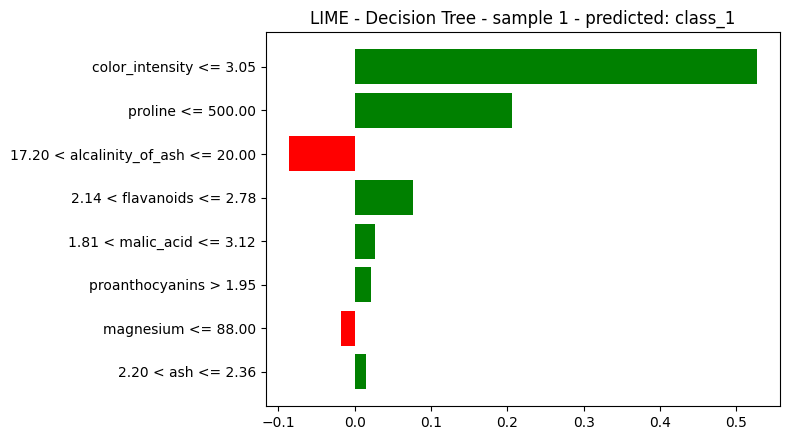

LIME  |  Model: Random Forest  |  Test sample: 1
True class      : class_1
Predicted class : class_1
Probabilities   : class_0=0.030, class_1=0.965, class_2=0.005
Local surrogate fit (R^2): 0.504   (closer to 1 = the simple model mimics the black box better here)

Features pushing TOWARDS 'class_1' (positive weights):


,Feature,LIME rule,Weight
0,color_intensity,color_intensity <= 3.05,0.2500
1,alcohol,alcohol <= 12.37,0.1736
2,proline,proline <= 500.00,0.1112
3,magnesium,magnesium <= 88.00,0.0606
4,hue,hue > 1.09,0.0504
5,flavanoids,2.14 < flavanoids <= 2.78,0.0299
6,od280/od315_of_diluted_wines,od280/od315_of_diluted_wines > 3.14,0.0118


Features pushing AWAY from 'class_1' (negative weights):


,Feature,LIME rule,Weight
0,malic_acid,1.81 < malic_acid <= 3.12,-0.0114


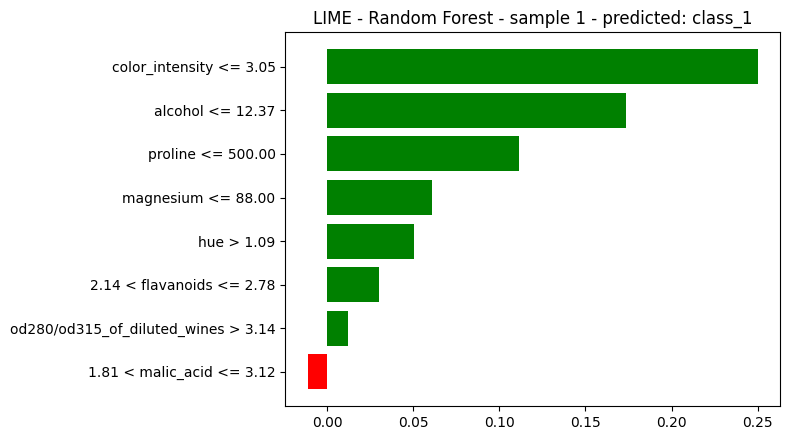

LIME  |  Model: Logistic Regression  |  Test sample: 1
True class      : class_1
Predicted class : class_1
Probabilities   : class_0=0.004, class_1=0.996, class_2=0.000
Local surrogate fit (R^2): 0.305   (closer to 1 = the simple model mimics the black box better here)

Features pushing TOWARDS 'class_1' (positive weights):


,Feature,LIME rule,Weight
0,alcohol,alcohol <= 12.37,0.2680
1,proline,proline <= 500.00,0.2507
2,color_intensity,color_intensity <= 3.05,0.2309
3,hue,hue > 1.09,0.1662
4,proanthocyanins,proanthocyanins > 1.95,0.0811
5,ash,2.20 < ash <= 2.36,0.0538


Features pushing AWAY from 'class_1' (negative weights):


,Feature,LIME rule,Weight
0,od280/od315_of_diluted_wines,od280/od315_of_diluted_wines > 3.14,-0.0711
1,nonflavanoid_phenols,nonflavanoid_phenols <= 0.27,-0.0442


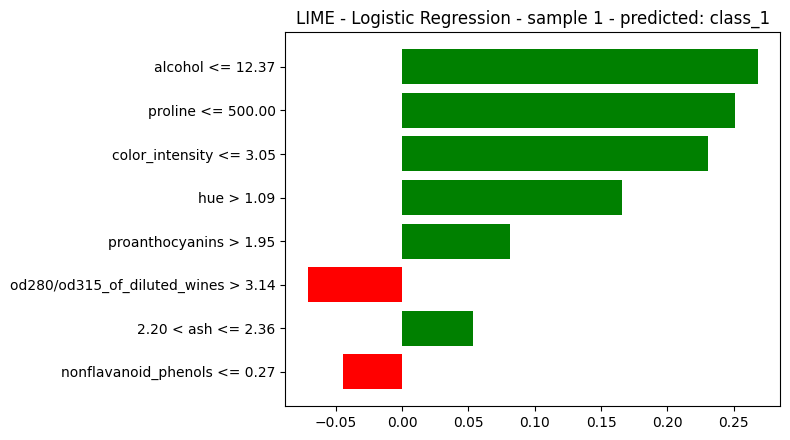

In [26]:
for name in models:
    show_lime(name, idx_2)

### 8.2 SHAP for Sample 2

SHAP  |  Model: Decision Tree  |  Test sample: 1
True class      : class_1
Predicted class : class_1   (probability = 1.000)
Base value (average model output for this class) : 0.398
Sum of SHAP values                                 : +0.602
Base + sum of SHAP = 1.000  (equals the predicted probability)

Features pushing the probability of 'class_1' UP (positive SHAP values):


,Feature,Feature value,SHAP value
0,color_intensity,2.15,0.3319
1,proline,290.00,0.1762
2,flavanoids,2.25,0.0526
3,malic_acid,2.83,0.0149
4,od280/od315_of_diluted_wines,3.30,0.0144
5,ash,2.22,0.0140


Features pushing the probability of 'class_1' DOWN (negative SHAP values):


,Feature,Feature value,SHAP value
6,alcalinity_of_ash,18.0,-0.0025


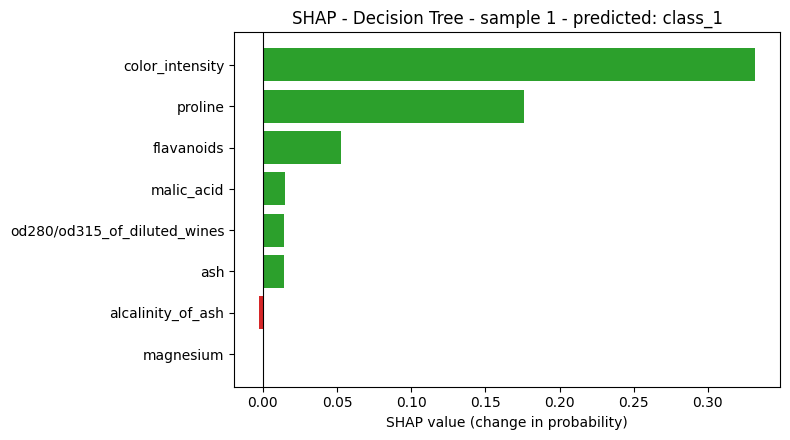

Waterfall plot: starts at the base value and adds each feature's SHAP value to reach the prediction.


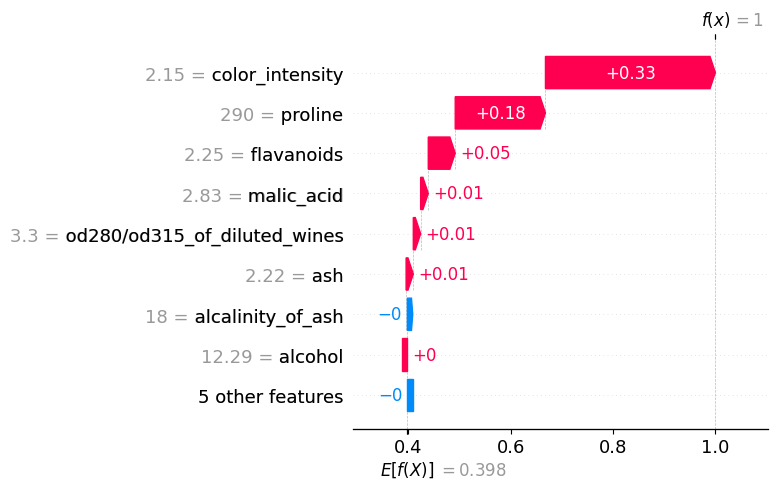

SHAP  |  Model: Random Forest  |  Test sample: 1
True class      : class_1
Predicted class : class_1   (probability = 0.965)
Base value (average model output for this class) : 0.398
Sum of SHAP values                                 : +0.567
Base + sum of SHAP = 0.965  (equals the predicted probability)

Features pushing the probability of 'class_1' UP (positive SHAP values):


,Feature,Feature value,SHAP value
0,color_intensity,2.15,0.1799
1,alcohol,12.29,0.1279
2,proline,290.00,0.1093
3,flavanoids,2.25,0.0647
4,hue,1.15,0.0438
5,od280/od315_of_diluted_wines,3.30,0.0258
6,magnesium,88.00,0.0248
8,proanthocyanins,1.99,0.0086


Features pushing the probability of 'class_1' DOWN (negative SHAP values):


,Feature,Feature value,SHAP value
7,malic_acid,2.83,-0.0159
10,nonflavanoid_phenols,0.25,-0.0071
11,alcalinity_of_ash,18.00,-0.0037


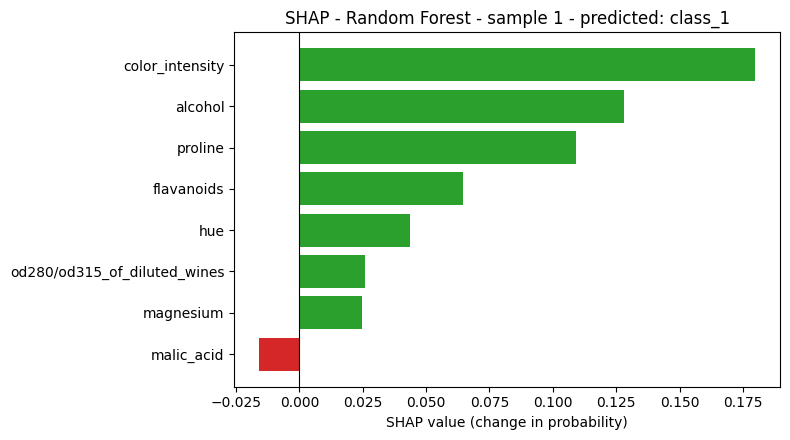

Waterfall plot: starts at the base value and adds each feature's SHAP value to reach the prediction.


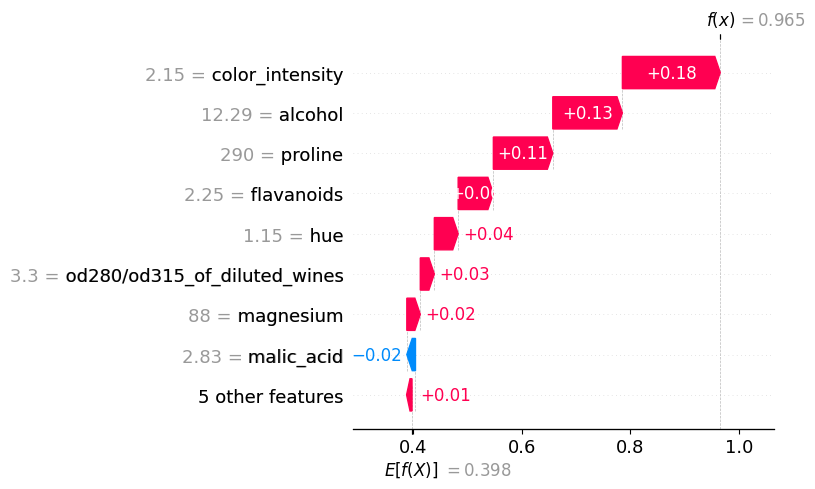

SHAP  |  Model: Logistic Regression  |  Test sample: 1
True class      : class_1
Predicted class : class_1   (probability = 0.996)
Base value (average model output for this class) : 0.459
Sum of SHAP values                                 : +0.538
Base + sum of SHAP = 0.996  (equals the predicted probability)

Features pushing the probability of 'class_1' UP (positive SHAP values):


,Feature,Feature value,SHAP value
0,proline,290.00,0.2392
1,color_intensity,2.15,0.1128
2,alcohol,12.29,0.0878
3,hue,1.15,0.0525
4,ash,2.22,0.0450
7,proanthocyanins,1.99,0.0179
8,flavanoids,2.25,0.0121
9,magnesium,88.00,0.0120


Features pushing the probability of 'class_1' DOWN (negative SHAP values):


,Feature,Feature value,SHAP value
5,od280/od315_of_diluted_wines,3.3,-0.0209
6,alcalinity_of_ash,18.0,-0.0207


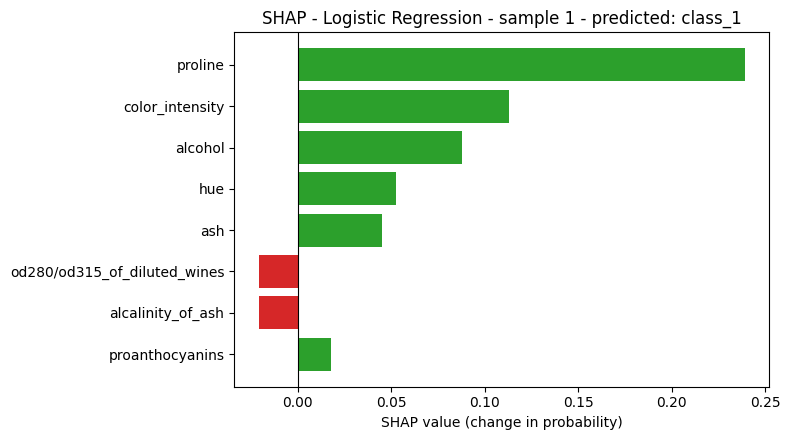

Waterfall plot: starts at the base value and adds each feature's SHAP value to reach the prediction.


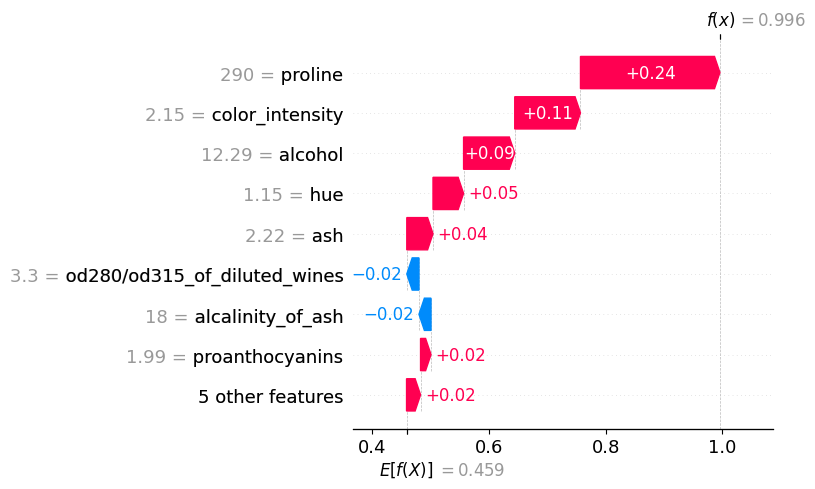

In [27]:
for name in models:
    show_shap(name, idx_2)

### 8.3 LIME vs SHAP for Sample 2

################################################################################
LIME vs SHAP | test sample 1 | true class: class_1
################################################################################

Decision Tree - predicted class: class_1


,Feature value,LIME weight,LIME rank,SHAP value,SHAP rank,Same sign?
color_intensity,2.15,0.5013,1,0.3319,1,yes
proline,290.00,0.2265,2,0.1762,2,yes
flavanoids,2.25,0.0717,4,0.0526,3,yes
alcalinity_of_ash,18.00,-0.0751,3,-0.0025,7,yes
malic_acid,2.83,0.0240,6,0.0149,4,yes
od280/od315_of_diluted_wines,3.30,-0.0192,7,0.0144,5,NO
alcohol,12.29,0.0352,5,0.0000,8,n/a
ash,2.22,-0.0096,9,0.0140,6,NO



Random Forest - predicted class: class_1


,Feature value,LIME weight,LIME rank,SHAP value,SHAP rank,Same sign?
color_intensity,2.15,0.2546,1,0.1799,1,yes
alcohol,12.29,0.1685,2,0.1279,2,yes
proline,290.00,0.1279,3,0.1093,3,yes
flavanoids,2.25,0.0272,6,0.0647,4,yes
hue,1.15,0.0560,4,0.0438,5,yes
magnesium,88.00,0.0504,5,0.0248,7,yes
od280/od315_of_diluted_wines,3.30,-0.0048,11,0.0258,6,NO
malic_acid,2.83,-0.0089,9,-0.0159,8,yes



Logistic Regression - predicted class: class_1


,Feature value,LIME weight,LIME rank,SHAP value,SHAP rank,Same sign?
proline,290.00,0.2524,1,0.2392,1,yes
color_intensity,2.15,0.2425,3,0.1128,2,yes
alcohol,12.29,0.2516,2,0.0878,3,yes
hue,1.15,0.1406,4,0.0525,4,yes
ash,2.22,0.0481,7,0.0450,5,yes
od280/od315_of_diluted_wines,3.30,-0.0692,6,-0.0209,6,yes
proanthocyanins,1.99,0.0715,5,0.0179,8,yes
magnesium,88.00,0.0435,9,0.0120,10,yes


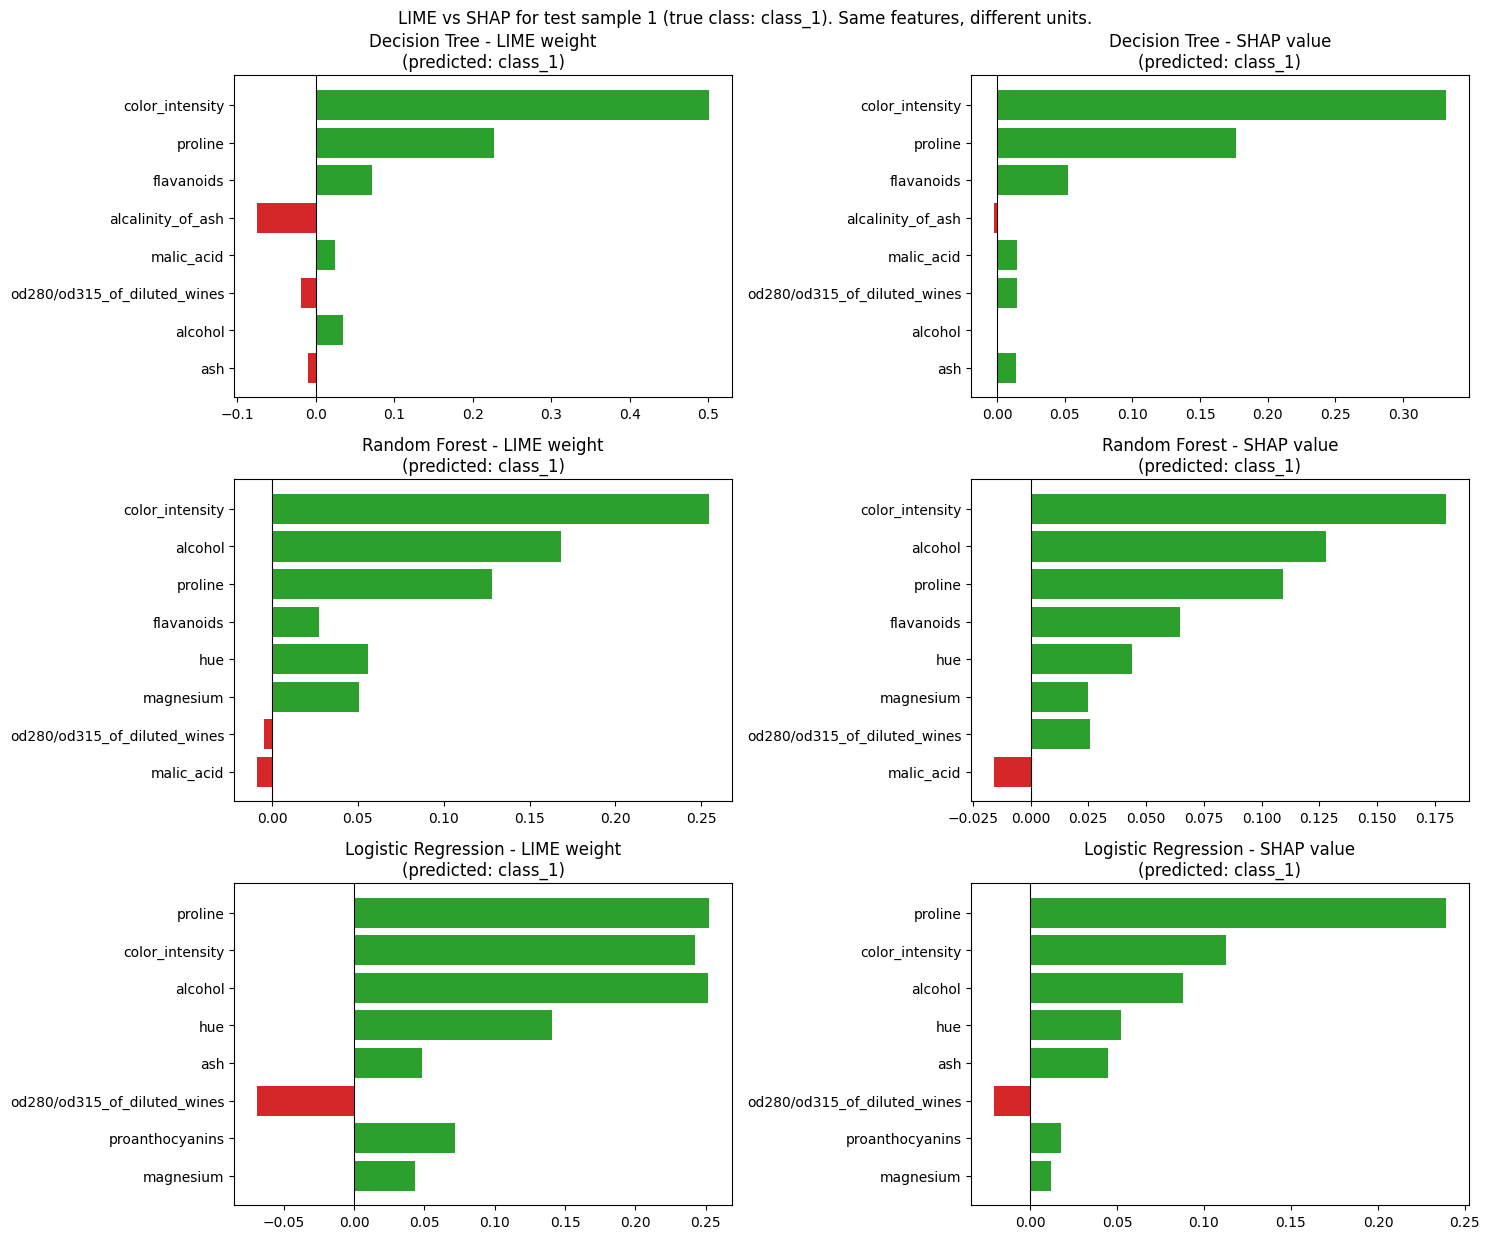

Agreement between LIME and SHAP for this sample:


,Spearman rank corr.,Top-3 overlap,Sign agreement (%)
Model,,,
Decision Tree,0.772,2,71.4
Random Forest,0.835,3,84.6
Logistic Regression,0.873,3,100.0


SHAP values per model - sample 1


,Decision Tree,Random Forest,Logistic Regression
color_intensity,0.3319,0.1799,0.1128
proline,0.1762,0.1093,0.2392
alcohol,0.0000,0.1279,0.0878
flavanoids,0.0526,0.0647,0.0121
hue,0.0000,0.0438,0.0525
ash,0.0140,0.0076,0.0450
od280/od315_of_diluted_wines,0.0144,0.0258,-0.0209
magnesium,0.0000,0.0248,0.0120
alcalinity_of_ash,-0.0025,-0.0037,-0.0207
proanthocyanins,0.0000,0.0086,0.0179


LIME weights per model - sample 1


,Decision Tree,Random Forest,Logistic Regression
Feature,,,
color_intensity,0.5013,0.2546,0.2425
proline,0.2265,0.1279,0.2524
alcohol,0.0352,0.1685,0.2516
hue,-0.0122,0.0560,0.1406
alcalinity_of_ash,-0.0751,-0.0100,-0.0157
flavanoids,0.0717,0.0272,0.0064
proanthocyanins,0.0070,0.0162,0.0715
od280/od315_of_diluted_wines,-0.0192,-0.0048,-0.0692
magnesium,-0.0049,0.0504,0.0435


In [28]:
run_comparison(idx_2)

print(f"SHAP values per model - sample {idx_2}")
display(cross_model_shap(idx_2).round(4))
print(f"LIME weights per model - sample {idx_2}")
display(cross_model_lime(idx_2).round(4))

### 8.4 Sample 1 vs Sample 2: how do the explanations change?

For each model, the table shows the top features and how their contribution changes when the sample changes. Positive = supports the predicted class, negative = opposes it. Both methods should show that **different samples are explained by different features** (and with different signs).

In [29]:
def change_table(model_name):
    out = {}
    for idx in (idx_1, idx_2):
        c = predicted_class(model_name, idx)
        out[f"LIME s{idx} ({class_names[c]})"] = lime_all_features(model_name, idx)
        out[f"SHAP s{idx} ({class_names[c]})"] = shap_series(model_name, idx)
    t = pd.DataFrame(out)
    return t.loc[t.abs().max(axis=1).sort_values(ascending=False).index].head(8).round(4)


for name in models:
    print("=" * 80)
    print(f"{name}: explanation of Sample {idx_1} vs Sample {idx_2}")
    print("=" * 80)
    display(change_table(name))

Decision Tree: explanation of Sample 0 vs Sample 1


,LIME s0 (class_0),SHAP s0 (class_0),LIME s1 (class_1),SHAP s1 (class_1)
color_intensity,0.1951,0.2578,0.5013,0.3319
flavanoids,0.1496,0.3348,0.0717,0.0526
proline,0.1765,0.0897,0.2265,0.1762
alcalinity_of_ash,0.0048,0.0000,-0.0751,-0.0025
malic_acid,-0.0378,-0.0057,0.0240,0.0149
alcohol,0.0107,0.0000,0.0352,0.0000
nonflavanoid_phenols,0.0265,0.0000,-0.0057,0.0000
od280/od315_of_diluted_wines,0.0237,-0.0038,-0.0192,0.0144


Random Forest: explanation of Sample 0 vs Sample 1


,LIME s0 (class_0),SHAP s0 (class_0),LIME s1 (class_1),SHAP s1 (class_1)
color_intensity,0.0723,0.1013,0.2546,0.1799
alcohol,0.1037,0.1162,0.1685,0.1279
proline,0.0607,0.1044,0.1279,0.1093
flavanoids,0.1086,0.1193,0.0272,0.0647
od280/od315_of_diluted_wines,0.0652,0.0577,-0.0048,0.0258
hue,0.0196,0.0354,0.0560,0.0438
magnesium,0.0247,0.0138,0.0504,0.0248
total_phenols,0.0305,0.0360,-0.0019,0.0009


Logistic Regression: explanation of Sample 0 vs Sample 1


,LIME s0 (class_0),SHAP s0 (class_0),LIME s1 (class_1),SHAP s1 (class_1)
proline,0.0480,0.1796,0.2524,0.2392
alcohol,0.0520,0.1377,0.2516,0.0878
color_intensity,0.0231,0.0133,0.2425,0.1128
od280/od315_of_diluted_wines,0.1506,0.1339,-0.0692,-0.0209
flavanoids,0.1505,0.0973,0.0064,0.0121
hue,-0.0132,-0.0187,0.1406,0.0525
alcalinity_of_ash,-0.0803,0.0000,-0.0157,-0.0207
proanthocyanins,-0.0113,0.0000,0.0715,0.0179


## 9. Quantitative summary and extra analysis (supports the discussion, Lab step 9)

### 9.1 Overall agreement between LIME and SHAP (both samples, all models)

In [30]:
metrics_df = pd.DataFrame(metric_rows).set_index(["Sample", "Model"])
display(metrics_df)

summary = metrics_df.groupby("Model")[["Spearman rank corr.", "Top-3 overlap", "Sign agreement (%)"]].mean().round(3)
print("Average over the two samples:")
display(summary)

print(f"Overall average sign agreement : {metrics_df['Sign agreement (%)'].mean():.1f}%")
print(f"Overall average rank correlation: {metrics_df['Spearman rank corr.'].mean():.2f}")
print(f"Overall average top-3 overlap   : {metrics_df['Top-3 overlap'].mean():.2f} of 3 features")
best = summary["Spearman rank corr."].idxmax()
worst = summary["Spearman rank corr."].idxmin()
print(f"LIME and SHAP agree most for the {best} (rank corr. {summary.loc[best, 'Spearman rank corr.']}) "
      f"and least for the {worst} (rank corr. {summary.loc[worst, 'Spearman rank corr.']}).")

Spearman rank corr.  Top-3 overlap  \
Sample Model                                                     
0      Decision Tree                      0.800              3   
       Random Forest                      0.923              2   
       Logistic Regression                0.492              1   
1      Decision Tree                      0.772              2   
       Random Forest                      0.835              3   
       Logistic Regression                0.873              3   

                            Sign agreement (%)  
Sample Model                                    
0      Decision Tree                      83.3  
       Random Forest                      92.3  
       Logistic Regression               100.0  
1      Decision Tree                      71.4  
       Random Forest                      84.6  
       Logistic Regression               100.0

Average over the two samples:


,Spearman rank corr.,Top-3 overlap,Sign agreement (%)
Model,,,
Decision Tree,0.786,2.5,77.35
Logistic Regression,0.682,2.0,100.00
Random Forest,0.879,2.5,88.45


Overall average sign agreement : 88.6%
Overall average rank correlation: 0.78
Overall average top-3 overlap   : 2.33 of 3 features
LIME and SHAP agree most for the Random Forest (rank corr. 0.879) and least for the Logistic Regression (rank corr. 0.682).


### 9.2 How stable is LIME? (and SHAP?)

LIME creates its perturbations **randomly**, so two runs can give slightly different weights. We explain the **same sample with the same model** five times with different random seeds and count how often each feature appears and how much its weight varies. A small `Std_weight` means a more stable explanation.

SHAP for tree models (`TreeExplainer`) has no randomness: repeated runs give **identical** values.

In [31]:
def lime_stability(model_name, idx, seeds=(0, 1, 2, 3, 4)):
    model = models[model_name]
    frames = []
    for s in seeds:
        exp_s, pred_s = lime_explain(model, idx, num_features=8, explainer_obj=make_explainer(seed=s))
        f = lime_to_frame(exp_s, pred_s)
        f["Run"] = s
        f["Rank"] = np.arange(1, len(f) + 1)
        frames.append(f)
    runs = pd.concat(frames)
    summ = runs.groupby("Feature").agg(
        Times_in_explanation=("Run", "count"),
        Mean_weight=("Weight", "mean"),
        Std_weight=("Weight", "std"),
        Best_rank=("Rank", "min"),
    )
    summ["abs_mean"] = summ["Mean_weight"].abs()
    summ = summ.sort_values(["Times_in_explanation", "abs_mean"], ascending=[False, False]).drop(columns="abs_mean")
    return summ.round(4)


print(f"LIME stability - Random Forest, sample {idx_1} (5 runs, different seeds)")
display(lime_stability("Random Forest", idx_1))

# SHAP (tree) is deterministic: recompute for the same sample and compare with the stored values
raw_again = shap.TreeExplainer(models["Random Forest"]).shap_values(X_test[[idx_1]], check_additivity=False)
if isinstance(raw_again, list):
    again = np.stack([np.asarray(r) for r in raw_again], axis=-1)
else:
    again = np.asarray(raw_again)
again = again.reshape(len(feature_names), len(class_names))
print("Maximum difference between two SHAP runs (Random Forest, sample 1):",
      float(np.abs(again - shap_3d["Random Forest"][idx_1]).max()))

LIME stability - Random Forest, sample 0 (5 runs, different seeds)


,Times_in_explanation,Mean_weight,Std_weight,Best_rank
Feature,,,,
flavanoids,5,0.1066,0.0074,1
alcohol,5,0.1046,0.0055,1
color_intensity,5,0.0754,0.0051,3
od280/od315_of_diluted_wines,5,0.0602,0.0093,3
proline,5,0.0500,0.0042,4
hue,5,0.0288,0.0046,6
total_phenols,5,0.0287,0.0037,6
magnesium,5,0.0228,0.0058,6


Maximum difference between two SHAP runs (Random Forest, sample 1): 0.0


### 9.3 Speed: LIME vs SHAP

In [32]:
speed = pd.DataFrame({
    "LIME seconds per explanation (avg)": {n: float(np.mean(t)) for n, t in lime_times.items()},
    "SHAP seconds per test sample (avg)": {n: shap_times[n] / len(X_test) for n in models},
}).round(4)
display(speed)
print("LIME needs thousands of model calls for every single explanation. "
      "Tree SHAP explains a whole test set quickly; Kernel SHAP (used for the Logistic Regression pipeline) is slower because it is a model-agnostic approximation.")

,LIME seconds per explanation (avg),SHAP seconds per test sample (avg)
Decision Tree,0.0930,0.0000
Random Forest,0.2155,0.0015
Logistic Regression,0.0790,0.0805


LIME needs thousands of model calls for every single explanation. Tree SHAP explains a whole test set quickly; Kernel SHAP (used for the Logistic Regression pipeline) is slower because it is a model-agnostic approximation.


## 10. Discussion: similarities and differences between LIME and SHAP (Lab step 9)

*Use the tables and charts in Sections 7 to 9 as evidence for these points.*

### 10.1 Similarities
- Both are **post-hoc, local explanation methods**: they explain one prediction of an already trained model.
- Both give **feature attributions with a direction and a size**: a feature can push the prediction towards the predicted class (positive) or away from it (negative).
- Both are **model-agnostic** in their general form, so they can explain a tree, a forest and a linear model (SHAP also has faster model-specific versions).
- Both usually **identify largely the same important features** for a sample. Check the top-3 overlap, rank correlation and sign agreement in Section 9.1: when they are high, the two methods support each other, and that increases our trust in the explanation.
- Both show that **explanations change from sample to sample** (Section 8.4): different samples are explained by different features.

### 10.2 Differences

| Aspect | LIME | SHAP |
|---|---|---|
| **Idea** | Fits a simple linear model on randomly perturbed copies of the sample | Computes each feature's fair share of the prediction (Shapley value from game theory) |
| **Theory** | Heuristic, with a local approximation | Based on fairness axioms (local accuracy, consistency, missingness) |
| **Output** | Weights for binned feature ranges such as `proline > 675` | Contribution of each feature value, in probability units |
| **Additivity** | Weights do **not** add up to the prediction | `base value + sum of SHAP values = prediction` (checked in Section 6.1) |
| **Reproducibility** | Random sampling, so results vary between runs (Section 9.2) | Tree SHAP is deterministic; Kernel SHAP is an approximation |
| **Speed** | Thousands of model calls per explanation | Very fast for trees; slower for Kernel SHAP (Section 9.3) |
| **Scope** | **Local** only | **Local and global**: averaging |SHAP| over many samples gives global importance (Section 6.4) |
| **Local fit quality** | A surrogate R² shows how well the simple model imitates the black box near the sample | No surrogate, so no fit problem |
| **Main weaknesses** | Instability, dependence on bins and kernel width, unrealistic perturbed samples | Cost of Kernel SHAP, and correlated features share credit in ways that are hard to interpret |

### 10.3 What the results show for this lab
- All three models are accurate, yet they do **not** have to rely on exactly the same features (compare the tables in Section 7.1 and the global plots in Section 6.4). A Decision Tree concentrates its SHAP values on the few features it actually splits on (features it never uses get exactly 0), a Random Forest typically spreads credit over more features, and Logistic Regression uses a smooth weighted sum in which many features contribute a little.
- LIME and SHAP should be compared by **direction (sign)** and by **which features rank as most important**, using the numbers in Section 9.1. Their **numeric sizes cannot be compared directly** because they are measured in different units.
- Perfect agreement is not expected. When it drops, typical reasons are features with very small contributions, the random sampling in LIME (Section 9.2), and the hard threshold rules of a Decision Tree. Quote the actual values from your run (Section 9.1) in your discussion.

### 10.4 Which one should be used?
- Use **SHAP** when you need **consistent, additive explanations**, global feature importance, or a result that does not change between runs. It is the better choice for tree models because it is fast and exact.
- Use **LIME** for a **quick, easy-to-read local explanation** of any black-box model, especially when only `predict_proba` is available. Run it more than once to check the explanation is stable.
- Using **both together**, as in this lab, is good practice: if both methods point to the same features, the explanation is more trustworthy.

### 10.5 Conclusion
Accuracy alone does not tell us *why* a model decides as it does. LIME and SHAP make each decision visible, show which chemical properties (such as proline, flavanoids and colour intensity) drive each wine classification, and let us check whether this makes chemical sense. SHAP gives a more principled, additive and also global view, while LIME gives a simple local approximation. Their agreement on the important features supports the reliability of the explanations.